In [31]:
# 그림 속 한글이 네모로 나오지 않게 (운영체제별 글꼴). 노트북에서 한 번만 실행
import platform
import pandas as pd
import matplotlib.pyplot as plt

fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}
name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

### ① 데이터 읽기 및 날짜 변환

In [32]:
df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

### ② 중복 행 제거

In [33]:
before = len(df)
df = df.drop_duplicates().copy()
print(before, "->", len(df))

1030 -> 1004


### ③ 잘못된 수량 22건 복원

In [34]:
bad = df["quantity"] > 100
df.loc[bad, "quantity"] = (df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]).round().astype(int)
diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()
print("고친 줄 :", bad.sum(), "수량 최대 :", df["quantity"].max(), "총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22 수량 최대 : 99 총액 안 맞는 줄 : 0


### ④ 날짜 오류 표시 및 정제 데이터 저장

In [35]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]
df.to_csv("sales_clean.csv", index=False)
print(df["date_error"].sum(), "건, ", df.shape)

147 건,  (1004, 15)


### ⑤ 배송 기간은 보통 며칠인가?

전체 유효 배송 기간 건수 : 852
평균 : 22.05 일 / 중앙값 : 2.0 일


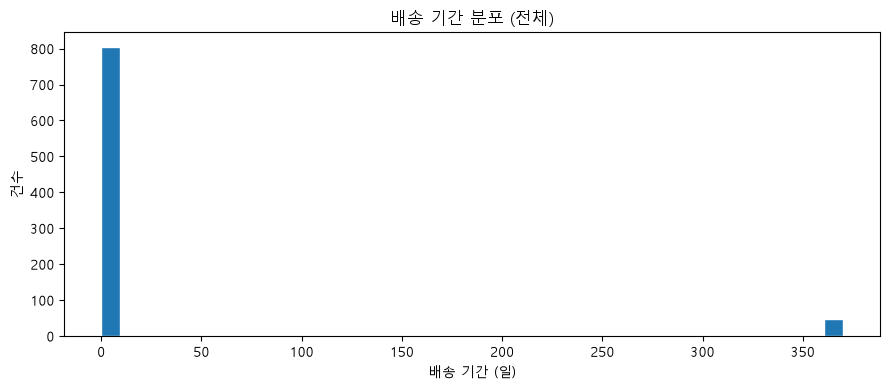

In [36]:
valid = df.loc[(~df["date_error"]) & df["delivery_date"].notna()].copy()
days = (valid["delivery_date"] - valid["shipping_date"]).dt.days
print("전체 유효 배송 기간 건수 :", len(days))
print("평균 :", round(days.mean(), 2), "일 / 중앙값 :", round(days.median(), 2), "일")
fig, ax = plt.subplots(figsize=(9, 4))
days.plot.hist(bins=40, ax=ax, edgecolor="white")
ax.set(title="배송 기간 분포 (전체)", xlabel="배송 기간 (일)", ylabel="건수")
plt.tight_layout()
plt.show()

#### 오른쪽 끝의 300일 초과 데이터 확인

In [37]:
long_days = days[days > 300]
print("300일 초과 건수 :", len(long_days))
print("300일 초과 기간의 범위 :", long_days.min(), "~", long_days.max(), "일")
print(valid.loc[long_days.index, ["shipping_date", "delivery_date", "status"]].assign(days=long_days).head().to_string(index=False))
normal_days = days[days <= 300]
print("300일 초과 제외 후 건수 :", len(normal_days))
print("제외 후 평균 :", round(normal_days.mean(), 2), "일 / 중앙값 :", round(normal_days.median(), 2), "일")

300일 초과 건수 : 47
300일 초과 기간의 범위 : 364 ~ 370 일
shipping_date delivery_date status  days
   2023-01-15    2024-01-15   배송완료   365
   2023-01-23    2024-01-27   배송완료   369
   2023-02-03    2024-02-03   배송완료   365
   2023-02-14    2024-02-17   배송완료   368
   2023-03-14    2024-03-12   배송완료   364
300일 초과 제외 후 건수 : 805
제외 후 평균 : 1.93 일 / 중앙값 : 2.0 일


- 날짜 오류와 결측 도착일을 제외한 852건의 배송 기간은 평균 **22.05일**, 중앙값 **2일**이다. 평균이 훨씬 큰 이유는 364~370일인 47건이 평균을 끌어올리기 때문이다.
- 이 47건은 배송일과 도착일의 연도가 약 1년 차이 나며 다른 주문은 0~5일에 집중되어 있어 날짜 입력 오류가 의심된다. 어느 날짜가 맞는지는 확인할 수 없으므로 **원본과 `sales_clean.csv`에서는 유지**하고, 보통 배송 기간 분석에서만 제외한다. 나머지 805건의 평균은 **1.93일**, 중앙값은 **2일**이다.

### ⑥ 만족도가 낮을수록 반품이 많은가?

              주문건수  반품건수  반품비율(%)
satisfaction                     
1.0            224    17     7.59
2.0            184    22    11.96
3.0            192    15     7.81
4.0            172    15     8.72
5.0            202    14     6.93


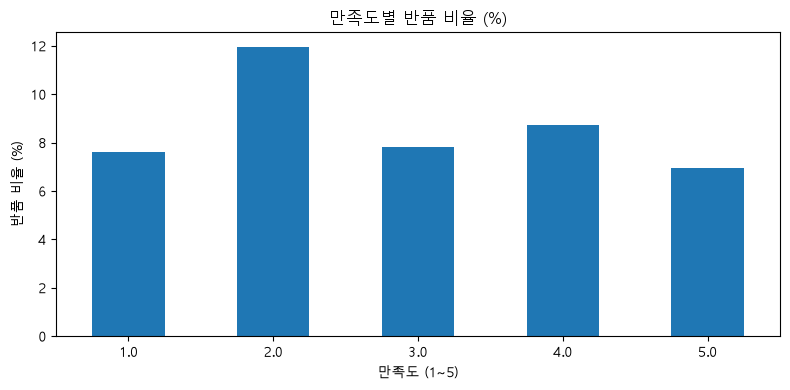

In [38]:
returns = df.assign(is_return=df["status"].eq("반품")).groupby("satisfaction").agg(주문건수=("is_return", "size"), 반품건수=("is_return", "sum"), 반품비율=("is_return", "mean"))
returns["반품비율(%)"] = returns["반품비율"] * 100
print(returns[["주문건수", "반품건수", "반품비율(%)"]].round(2).to_string())
ax = returns["반품비율(%)"].plot.bar(figsize=(8, 4), rot=0, title="만족도별 반품 비율 (%)")
ax.set(xlabel="만족도 (1~5)", ylabel="반품 비율 (%)")
plt.tight_layout()
plt.show()

- 만족도가 낮을수록 반품 비율이 일관되게 높아지는 것은 **아니다**. 만족도 1점은 **7.59%**, 2점은 **11.96%**, 3점은 **7.81%**, 4점은 **8.72%**, 5점은 **6.93%**이다.
- 2점이 가장 높지만 1점은 3점과 4점보다 낮다. 따라서 이 데이터만으로 만족도 하락에 따른 반품률의 단조로운 증가를 주장할 수 없다.

### ⑦ 카테고리 매출 1위의 이유는 건수·단가·수량 중 무엇인가?

In [39]:
category_summary = df.groupby("category").agg(주문건수=("total_sales", "size"), 총매출=("total_sales", "sum"), 평균단가=("unit_price", "mean"), 평균수량=("quantity", "mean"))
category_summary["총매출(억원)"] = category_summary["총매출"] / 1e8
category_summary = category_summary.sort_values("총매출", ascending=False)
print(category_summary[["주문건수", "총매출(억원)", "평균단가", "평균수량"]].round(2).to_string())

          주문건수  총매출(억원)       평균단가   평균수량
category                                 
가구         213    28.43  257322.91  51.04
식품         210    25.13  255232.93  47.31
전자제품       207    24.72  249651.61  47.96
도서         204    24.53  238500.64  49.50
의류         170    21.82  249447.16  51.61


- 매출 1위는 **가구(약 28.43억 원)**이다. 가구는 **213건**으로 주문 건수가 가장 많고, 평균 단가도 **약 257,323원**으로 가장 높다.
- 평균 수량은 **약 51.04개**로 의류(약 51.61개)보다 낮다. 따라서 가구의 1위는 수량 하나보다 **많은 주문 건수와 높은 평균 단가**가 함께 기여한 결과로 해석할 수 있다.